# RemixFormer++ ISIC19 Dermoscopy Pretraining - Kaggle Fixed
## ImageNet Initialization → DINO Self-Supervised Pretraining → Supervised ISIC19

This notebook is a clean, dependency-ordered implementation for the dermoscopy branch.

### Pipeline

```text
ISIC19 dermoscopy
      ↓
ImageNet-pretrained ViT-S/16
      ↓
DINO self-supervised pretraining
      ↓
DINO-pretrained ViT-S/16
      ↓
HRWE + MSTA + Region Transformer
      ↓
Supervised ISIC19 training
      ↓
Transfer-ready dermoscopy encoder
      ↓
Full Derm7pt RemixFormer++
```

### Architecture used for the dermoscopy branch

- Input: 1024 × 1024
- 16 non-overlapping windows
- Window size: 256 × 256
- HRWE: ViT-S/16
- Embedding dimension: 384
- Transformer depth: 12
- Attention heads: 6
- Patch size: 16
- 256 patch tokens + 1 CLS token per window
- MSTA: 32 learnable templates
- Region-level transformer: 16 window tokens + 1 CLS token = 17 tokens
- Global dermoscopy feature: 384-D
- ISIC19 classifier: 8 classes

### Initialization

The HRWE ViT-S/16 starts from ImageNet-pretrained weights. A separate DINO teacher/student stage is then trained on ISIC19. The DINO teacher backbone is transferred into the supervised dermoscopy model.

This is a paper-aligned implementation of the requested ImageNet + DINO sequence. It should not be described as the authors' exact unpublished DINO checkpoint or exact training recipe.


## IMPORTANT: Run order

Run this notebook **from top to bottom**.

The cells are intentionally arranged so dependencies are created before they are used:

**Imports → Configuration → Data discovery → Train/validation split → DINO dataset → ImageNet ViT → DINO model → DINO training → Supervised model → Evaluation → Export**

If Kaggle was previously run out of order, restart the kernel/session before using **Run All**.


In [1]:
# ============================================================
# 01. INSTALL / IMPORTS
# ============================================================
import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "timm", "scikit-learn", "pandas",
        "matplotlib", "seaborn", "pillow"
    ],
    check=True
)

import os
import gc
import json
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.10.0+cu128
timm: 1.0.26
CUDA available: True
GPU: Tesla T4


In [2]:
# ============================================================
# 02. CONFIGURATION
# ============================================================

SEED = 42

DATA_ROOT = Path(
    "/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification"
)

OUTPUT_ROOT = Path(
    "/kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# RUN MODE
# ------------------------------------------------------------
# True  = small 2 + 2 epoch smoke test
# False = full dataset and longer training
RUN_TRIAL = True

TRIAL_TRAIN_SAMPLES = 512
TRIAL_VAL_SAMPLES = 128

# ------------------------------------------------------------
# DINO
# ------------------------------------------------------------
DINO_EPOCHS = 2 if RUN_TRIAL else 20
DINO_BATCH_SIZE = 8
DINO_LR = 1e-4
DINO_WEIGHT_DECAY = 1e-4

DINO_TEACHER_MOMENTUM = 0.996
DINO_TEACHER_TEMP = 0.04
DINO_STUDENT_TEMP = 0.1
DINO_CENTER_MOMENTUM = 0.9

# Smaller output dimension keeps the Kaggle smoke test practical.
# Increase to the desired DINO output dimension for a larger final run.
DINO_OUT_DIM = 16384

DINO_GLOBAL_SIZE = 224
DINO_LOCAL_SIZE = 96
DINO_NUM_LOCAL_CROPS = 2

# ------------------------------------------------------------
# SUPERVISED ISIC19
# ------------------------------------------------------------
SUP_EPOCHS = 50 if RUN_TRIAL else 50
SUP_BATCH_SIZE = 2
SUP_LR = 1e-4
SUP_MOMENTUM = 0.9
SUP_WEIGHT_DECAY = 0.0

NUM_WORKERS = 2
WINDOW_MICRO_BATCH = 8
AMP_ENABLED = True

# ------------------------------------------------------------
# REMIXFORMER++ DERMOSCOPY ARCHITECTURE
# ------------------------------------------------------------
IMAGE_SIZE = 1024
WINDOW_SIZE = 256
GRID_SIZE = 4
NUM_WINDOWS = 16

EMBED_DIM = 384
DEPTH = 12
NUM_HEADS = 6
PATCH_SIZE = 16
MSTA_K = 32
NUM_CLASSES = 8

CLASS_NAMES = [
    "MEL", "NV", "BCC", "AK",
    "BKL", "DF", "VASC", "SCC"
]

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert IMAGE_SIZE == GRID_SIZE * WINDOW_SIZE
assert WINDOW_SIZE % PATCH_SIZE == 0
assert EMBED_DIM == 384
assert DEPTH == 12
assert NUM_HEADS == 6
assert MSTA_K == 32
assert NUM_CLASSES == 8

print("RUN_TRIAL:", RUN_TRIAL)
print("DINO epochs:", DINO_EPOCHS)
print("Supervised epochs:", SUP_EPOCHS)
print("Device:", DEVICE)


RUN_TRIAL: True
DINO epochs: 2
Supervised epochs: 50
Device: cuda


In [3]:
# ============================================================
# 03. REPRODUCIBILITY
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("Seed:", SEED)


Seed: 42


In [4]:
# ============================================================
# 04. DISCOVER ISIC19 DATA
# ============================================================

gt_candidates = list(
    DATA_ROOT.rglob("ISIC_2019_Training_GroundTruth.csv")
)

if not gt_candidates:
    gt_candidates = list(
        DATA_ROOT.rglob("*Training_GroundTruth*.csv")
    )

if not gt_candidates:
    raise FileNotFoundError(
        f"ISIC19 ground-truth CSV not found under: {DATA_ROOT}"
    )

GT_CSV = gt_candidates[0]
print("Ground-truth CSV:", GT_CSV)

df = pd.read_csv(GT_CSV)

LABEL_COLUMNS = [
    "MEL", "NV", "BCC", "AK",
    "BKL", "DF", "VASC", "SCC"
]

missing = [
    c for c in LABEL_COLUMNS
    if c not in df.columns
]

if missing:
    raise ValueError(
        f"Missing ISIC19 label columns: {missing}"
    )

if "image" not in df.columns:
    raise ValueError(
        "The ground-truth CSV does not contain the 'image' column."
    )

df["label"] = (
    df[LABEL_COLUMNS]
    .values
    .argmax(axis=1)
)

# Robust image discovery.
image_files = {}

for pattern in ("*.jpg", "*.JPG", "*.jpeg", "*.JPEG"):
    for p in DATA_ROOT.rglob(pattern):
        image_files[p.stem] = p

print("Discovered image files:", len(image_files))

def resolve_image(image_id):
    stem = Path(str(image_id)).stem
    return str(image_files[stem]) if stem in image_files else None

df["path"] = df["image"].map(resolve_image)

missing_images = int(df["path"].isna().sum())

if missing_images:
    print("Rows with missing image files:", missing_images)

df = (
    df[df["path"].notna()]
    .reset_index(drop=True)
)

print("Usable ISIC19 images:", len(df))

print("\nFull class distribution:")
print(
    df["label"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

if len(df) < 100:
    raise RuntimeError(
        "Too few usable images were found. Check DATA_ROOT."
    )


Ground-truth CSV: /kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification/ISIC_2019_Training_GroundTruth.csv
Discovered image files: 25331
Usable ISIC19 images: 25331

Full class distribution:
label
MEL      4522
NV      12875
BCC      3323
AK        867
BKL      2624
DF        239
VASC      253
SCC       628
Name: count, dtype: int64


In [5]:
# ============================================================
# 05. STRATIFIED TRAIN / VALIDATION SPLIT
# ============================================================

if "df" not in globals():
    raise RuntimeError(
        "df is not defined. Run Cell 04 first."
    )

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

if RUN_TRIAL:
    n_train = min(
        TRIAL_TRAIN_SAMPLES,
        len(train_df)
    )
    n_val = min(
        TRIAL_VAL_SAMPLES,
        len(val_df)
    )

    train_df, _ = train_test_split(
        train_df,
        train_size=n_train,
        random_state=SEED,
        stratify=train_df["label"]
    )

    val_df, _ = train_test_split(
        val_df,
        train_size=n_val,
        random_state=SEED,
        stratify=val_df["label"]
    )

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTrain distribution:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

print("\nValidation distribution:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

train_df.to_csv(
    OUTPUT_ROOT / "train_split.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_ROOT / "val_split.csv",
    index=False
)


Train samples: 512
Validation samples: 128

Train distribution:
label
MEL      91
NV      260
BCC      67
AK       18
BKL      53
DF        5
VASC      5
SCC      13
Name: count, dtype: int64

Validation distribution:
label
MEL     23
NV      65
BCC     17
AK       5
BKL     13
DF       1
VASC     1
SCC      3
Name: count, dtype: int64


# 06. DINO SELF-SUPERVISED PRETRAINING

The DINO stage uses:

- ImageNet-initialized ViT-S/16
- two global crops
- two local crops
- student network updated by gradient descent
- teacher network updated by EMA
- centered teacher probabilities
- cross-view self-distillation

**Important:** the teacher is created as a separate model and initialized with `load_state_dict()`. We deliberately do **not** use `copy.deepcopy(student)`, because PyTorch 2.x can reject deep-copying non-leaf tensors created by some parameterization utilities.


In [6]:
# ============================================================
# 07. DINO DATASET
# ============================================================

if "train_df" not in globals():
    raise RuntimeError(
        "train_df is not defined. Run Cell 05 first."
    )

class DINOImageDataset(Dataset):

    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

        self.global_transform = transforms.Compose([
            transforms.RandomResizedCrop(
                DINO_GLOBAL_SIZE,
                scale=(0.45, 1.0),
                interpolation=InterpolationMode.BICUBIC
            ),
            transforms.RandomHorizontalFlip(),
            transforms.RandomApply(
                [
                    transforms.ColorJitter(
                        0.4, 0.4, 0.2, 0.1
                    )
                ],
                p=0.8
            ),
            transforms.RandomGrayscale(p=0.2),
            transforms.RandomApply(
                [
                    transforms.GaussianBlur(
                        kernel_size=23,
                        sigma=(0.1, 2.0)
                    )
                ],
                p=0.5
            ),
            transforms.ToTensor(),
            transforms.Normalize(
                IMAGENET_MEAN,
                IMAGENET_STD
            )
        ])

        self.local_transform = transforms.Compose([
            transforms.RandomResizedCrop(
                DINO_LOCAL_SIZE,
                scale=(0.05, 0.45),
                interpolation=InterpolationMode.BICUBIC
            ),
            transforms.RandomHorizontalFlip(),
            transforms.RandomApply(
                [
                    transforms.ColorJitter(
                        0.4, 0.4, 0.2, 0.1
                    )
                ],
                p=0.8
            ),
            transforms.RandomGrayscale(p=0.2),
            transforms.RandomApply(
                [
                    transforms.GaussianBlur(
                        kernel_size=9,
                        sigma=(0.1, 2.0)
                    )
                ],
                p=0.5
            ),
            transforms.ToTensor(),
            transforms.Normalize(
                IMAGENET_MEAN,
                IMAGENET_STD
            )
        ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        path = self.frame.iloc[idx]["path"]

        with Image.open(path) as im:
            img = im.convert("RGB")

        crops = [
            self.global_transform(img),
            self.global_transform(img)
        ]

        for _ in range(DINO_NUM_LOCAL_CROPS):
            crops.append(
                self.local_transform(img)
            )

        return crops


def dino_collate(batch):
    n_crops = len(batch[0])

    return [
        torch.stack(
            [sample[crop_idx] for sample in batch]
        )
        for crop_idx in range(n_crops)
    ]


dino_dataset = DINOImageDataset(train_df)

dino_loader = DataLoader(
    dino_dataset,
    batch_size=DINO_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    collate_fn=dino_collate,
    persistent_workers=(NUM_WORKERS > 0)
)

print("DINO samples:", len(dino_dataset))
print("DINO batches:", len(dino_loader))


DINO samples: 512
DINO batches: 64


In [7]:
# ============================================================
# 08. IMAGENET-PRETRAINED ViT-S/16
# ============================================================

def create_imagenet_vits16():
    # dynamic_img_size=True is required for DINO multi-crop training.
    # It allows the same ViT-S/16 to process 224x224 global crops
    # and 96x96 local crops while interpolating positional embeddings.
    model = timm.create_model(
        "vit_small_patch16_224",
        pretrained=True,
        num_classes=0,
        global_pool="",
        dynamic_img_size=True
    )

    return model


imagenet_vit = create_imagenet_vits16()

print(
    "ImageNet ViT-S/16 embedding:",
    imagenet_vit.num_features
)

assert imagenet_vit.num_features == EMBED_DIM

del imagenet_vit
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

ImageNet ViT-S/16 embedding: 384


In [8]:
# ============================================================
# 09. DINO HEAD + STUDENT + TEACHER
# ============================================================

class DINOHead(nn.Module):

    def __init__(
        self,
        in_dim,
        hidden_dim=2048,
        bottleneck_dim=256,
        out_dim=DINO_OUT_DIM
    ):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(
                hidden_dim,
                bottleneck_dim
            )
        )

        # Ordinary Linear is deliberately used.
        # This avoids PyTorch 2.x deepcopy/parameterization issues.
        self.last_layer = nn.Linear(
            bottleneck_dim,
            out_dim,
            bias=False
        )

        nn.init.normal_(
            self.last_layer.weight,
            std=0.02
        )

    def forward(self, x):
        x = self.mlp(x)
        x = F.normalize(x, dim=-1)
        return self.last_layer(x)


class DINOModel(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        self.backbone = backbone

        self.head = DINOHead(
            backbone.num_features
        )

    def forward(self, x):

        # timm dynamic_img_size=True allows 224 and 96 crops.
        tokens = self.backbone.forward_features(x)

        if tokens.ndim != 3:
            raise RuntimeError(
                f"Expected ViT tokens [B,N,D], got {tokens.shape}"
            )

        cls = tokens[:, 0]

        return self.head(cls)


def create_dino_model():

    backbone = timm.create_model(
        "vit_small_patch16_224",
        pretrained=True,
        num_classes=0,
        global_pool="",
        dynamic_img_size=True
    )

    assert backbone.num_features == EMBED_DIM

    return DINOModel(backbone)


# ------------------------------------------------------------
# Student: ImageNet initialized
# ------------------------------------------------------------
student = create_dino_model().to(DEVICE)


# ------------------------------------------------------------
# Teacher: separate ImageNet initialized model
# ------------------------------------------------------------
# DO NOT use copy.deepcopy(student).
teacher = create_dino_model().to(DEVICE)

teacher.load_state_dict(
    student.state_dict(),
    strict=True
)

for parameter in teacher.parameters():
    parameter.requires_grad = False

teacher.eval()

print(
    "Student parameters:",
    f"{sum(p.numel() for p in student.parameters()) / 1e6:.2f} M"
)

print(
    "Teacher parameters:",
    f"{sum(p.numel() for p in teacher.parameters()) / 1e6:.2f} M"
)

print(
    "Teacher initialization: copied from ImageNet-initialized student "
    "using load_state_dict()."
)

print(
    "DINO multi-crop mode: dynamic positional-embedding interpolation enabled."
)


Student parameters: 31.37 M
Teacher parameters: 31.37 M
Teacher initialization: copied from ImageNet-initialized student using load_state_dict().
DINO multi-crop mode: dynamic positional-embedding interpolation enabled.


In [9]:
# ============================================================
# 10. DINO LOSS
# ============================================================

class DINOLoss(nn.Module):

    def __init__(
        self,
        out_dim,
        student_temp=0.1,
        teacher_temp=0.04,
        center_momentum=0.9
    ):
        super().__init__()

        self.student_temp = student_temp
        self.teacher_temp = teacher_temp
        self.center_momentum = center_momentum

        self.register_buffer(
            "center",
            torch.zeros(1, out_dim)
        )

    @torch.no_grad()
    def update_center(self, teacher_output):

        batch_center = teacher_output.mean(
            dim=0,
            keepdim=True
        )

        self.center.mul_(
            self.center_momentum
        ).add_(
            batch_center,
            alpha=1.0 - self.center_momentum
        )

    def forward(
        self,
        student_output,
        teacher_output,
        batch_size
    ):

        n_crops = 2 + DINO_NUM_LOCAL_CROPS

        if student_output.shape[0] != batch_size * n_crops:
            raise RuntimeError(
                f"Student DINO output has {student_output.shape[0]} rows, "
                f"expected {batch_size * n_crops}."
            )

        if teacher_output.shape[0] != batch_size * 2:
            raise RuntimeError(
                f"Teacher DINO output has {teacher_output.shape[0]} rows, "
                f"expected {batch_size * 2}."
            )

        student_chunks = student_output.chunk(
            n_crops,
            dim=0
        )

        teacher_chunks = teacher_output.chunk(
            2,
            dim=0
        )

        student_log_probs = [
            F.log_softmax(
                chunk / self.student_temp,
                dim=-1
            )
            for chunk in student_chunks
        ]

        teacher_probs = [
            F.softmax(
                (
                    chunk - self.center
                ) / self.teacher_temp,
                dim=-1
            ).detach()
            for chunk in teacher_chunks
        ]

        total_loss = 0.0
        n_terms = 0

        for teacher_view, teacher_prob in enumerate(
            teacher_probs
        ):

            for student_view, student_log_prob in enumerate(
                student_log_probs
            ):

                if student_view == teacher_view:
                    continue

                cross_entropy = torch.sum(
                    -teacher_prob * student_log_prob,
                    dim=-1
                ).mean()

                total_loss += cross_entropy
                n_terms += 1

        loss = total_loss / max(n_terms, 1)

        with torch.no_grad():
            self.update_center(
                teacher_output.detach()
            )

        return loss


dino_criterion = DINOLoss(
    out_dim=DINO_OUT_DIM,
    student_temp=DINO_STUDENT_TEMP,
    teacher_temp=DINO_TEACHER_TEMP,
    center_momentum=DINO_CENTER_MOMENTUM
).to(DEVICE)

dino_optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=DINO_LR,
    weight_decay=DINO_WEIGHT_DECAY
)

print("DINO loss and optimizer ready.")


DINO loss and optimizer ready.


In [10]:
# ============================================================
# 10B. DINO MULTI-CROP PREFLIGHT
# ============================================================
# This catches the exact resolution problem before any training.

test_global = torch.randn(
    1, 3,
    DINO_GLOBAL_SIZE,
    DINO_GLOBAL_SIZE,
    device=DEVICE
)

test_local = torch.randn(
    1, 3,
    DINO_LOCAL_SIZE,
    DINO_LOCAL_SIZE,
    device=DEVICE
)

student.eval()
teacher.eval()

with torch.no_grad():

    test_global_out = student(
        test_global
    )

    test_local_out = student(
        test_local
    )

assert test_global_out.shape == (
    1,
    DINO_OUT_DIM
)

assert test_local_out.shape == (
    1,
    DINO_OUT_DIM
)

print(
    f"Global crop {DINO_GLOBAL_SIZE}x{DINO_GLOBAL_SIZE} "
    f"-> {tuple(test_global_out.shape)}"
)

print(
    f"Local crop {DINO_LOCAL_SIZE}x{DINO_LOCAL_SIZE} "
    f"-> {tuple(test_local_out.shape)}"
)

del test_global, test_local
del test_global_out, test_local_out

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

student.train()
teacher.eval()

print("DINO MULTI-CROP PREFLIGHT PASSED.")


Global crop 224x224 -> (1, 16384)
Local crop 96x96 -> (1, 16384)
DINO MULTI-CROP PREFLIGHT PASSED.


In [11]:
# ============================================================
# 11. DINO TRAINING
# ============================================================
# DINO uses multi-crop inputs:
#   global crops = 224x224
#   local crops  = 96x96
#
# The image tensors must NOT be concatenated before the ViT.
# The ViT is configured with dynamic_img_size=True, so it can
# process both resolutions and interpolate positional embeddings.
#
# We concatenate ONLY the resulting DINO feature vectors.

def dino_momentum(step, total_steps):
    if total_steps <= 1:
        return 1.0

    return 1.0 - (
        1.0 - DINO_TEACHER_MOMENTUM
    ) * (
        math.cos(
            math.pi * step / (total_steps - 1)
        ) + 1.0
    ) / 2.0


dino_history = []

total_steps = (
    DINO_EPOCHS *
    max(len(dino_loader), 1)
)

global_step = 0

for epoch in range(1, DINO_EPOCHS + 1):

    student.train()
    teacher.eval()

    running_loss = 0.0

    for batch_idx, crops in enumerate(dino_loader):

        crops = [
            crop.to(
                DEVICE,
                non_blocking=True
            )
            for crop in crops
        ]

        if len(crops) != 4:
            raise RuntimeError(
                f"Expected 4 DINO crops, got {len(crops)}."
            )

        batch_size = crops[0].shape[0]

        # Check expected crop sizes.
        expected_sizes = [
            DINO_GLOBAL_SIZE,
            DINO_GLOBAL_SIZE,
            DINO_LOCAL_SIZE,
            DINO_LOCAL_SIZE
        ]

        for crop_idx, crop in enumerate(crops):

            actual_hw = tuple(
                crop.shape[-2:]
            )

            expected_hw = (
                expected_sizes[crop_idx],
                expected_sizes[crop_idx]
            )

            if actual_hw != expected_hw:
                raise RuntimeError(
                    f"DINO crop {crop_idx} has shape "
                    f"{actual_hw}, expected {expected_hw}."
                )

        dino_optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Student
        # Each resolution is processed independently.
        # Result for each crop is [B, DINO_OUT_DIM].
        # ----------------------------------------------------
        student_outputs = []

        for crop_idx, crop in enumerate(crops):

            student_crop_output = student(crop)

            if student_crop_output.shape != (
                batch_size,
                DINO_OUT_DIM
            ):
                raise RuntimeError(
                    f"Unexpected student output for crop "
                    f"{crop_idx}: "
                    f"{tuple(student_crop_output.shape)}"
                )

            student_outputs.append(
                student_crop_output
            )

        student_output = torch.cat(
            student_outputs,
            dim=0
        )

        # ----------------------------------------------------
        # Teacher
        # Only the two global crops are used.
        # ----------------------------------------------------
        with torch.no_grad():

            teacher_outputs = []

            for crop_idx, crop in enumerate(crops[:2]):

                teacher_crop_output = teacher(crop)

                if teacher_crop_output.shape != (
                    batch_size,
                    DINO_OUT_DIM
                ):
                    raise RuntimeError(
                        f"Unexpected teacher output for crop "
                        f"{crop_idx}: "
                        f"{tuple(teacher_crop_output.shape)}"
                    )

                teacher_outputs.append(
                    teacher_crop_output
                )

            teacher_output = torch.cat(
                teacher_outputs,
                dim=0
            )

        # ----------------------------------------------------
        # DINO loss
        # ----------------------------------------------------
        loss = dino_criterion(
            student_output,
            teacher_output,
            batch_size
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite DINO loss at "
                f"epoch {epoch}, "
                f"batch {batch_idx}: "
                f"{loss.item()}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            student.parameters(),
            max_norm=3.0
        )

        dino_optimizer.step()

        # ----------------------------------------------------
        # EMA teacher update
        # ----------------------------------------------------
        momentum = dino_momentum(
            global_step,
            total_steps
        )

        with torch.no_grad():

            for student_param, teacher_param in zip(
                student.parameters(),
                teacher.parameters()
            ):

                teacher_param.data.mul_(
                    momentum
                ).add_(
                    student_param.data,
                    alpha=1.0 - momentum
                )

        running_loss += loss.item()
        global_step += 1

        if (
            batch_idx == 0 or
            (batch_idx + 1) % 25 == 0
        ):

            print(
                f"DINO Epoch {epoch:02d}/{DINO_EPOCHS} | "
                f"Batch {batch_idx+1}/{len(dino_loader)} | "
                f"Loss {loss.item():.5f} | "
                f"Teacher m {momentum:.5f}"
            )

    epoch_loss = (
        running_loss /
        max(len(dino_loader), 1)
    )

    dino_history.append({
        "epoch": epoch,
        "loss": epoch_loss
    })

    print(
        f"DINO Epoch {epoch:02d}/{DINO_EPOCHS} | "
        f"Mean Loss {epoch_loss:.5f}"
    )

dino_history_df = pd.DataFrame(
    dino_history
)

dino_history_df.to_csv(
    OUTPUT_ROOT / "dino_history.csv",
    index=False
)

DINO_BACKBONE_PATH = (
    OUTPUT_ROOT /
    "DINO_ViT_S16_backbone.pth"
)

torch.save(
    {
        "model_name": "ViT-S/16",
        "embed_dim": EMBED_DIM,
        "depth": DEPTH,
        "heads": NUM_HEADS,
        "patch_size": PATCH_SIZE,
        "initialization": "ImageNet pretrained",
        "self_supervised_method": "DINO",
        "state_dict": teacher.backbone.state_dict()
    },
    DINO_BACKBONE_PATH
)

print(
    "Saved DINO backbone:",
    DINO_BACKBONE_PATH
)


DINO Epoch 01/2 | Batch 1/64 | Loss 9.67004 | Teacher m 0.99600
DINO Epoch 01/2 | Batch 25/64 | Loss 9.70629 | Teacher m 0.99634
DINO Epoch 01/2 | Batch 50/64 | Loss 9.69421 | Teacher m 0.99730
DINO Epoch 01/2 | Mean Loss 9.69729
DINO Epoch 02/2 | Batch 1/64 | Loss 9.69725 | Teacher m 0.99802
DINO Epoch 02/2 | Batch 25/64 | Loss 9.69463 | Teacher m 0.99914
DINO Epoch 02/2 | Batch 50/64 | Loss 9.69714 | Teacher m 0.99988
DINO Epoch 02/2 | Mean Loss 9.69503
Saved DINO backbone: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy/DINO_ViT_S16_backbone.pth


# 12. SUPERVISED ISIC19 DERMOSCOPY

Now the DINO-pretrained **ViT-S/16 backbone** is transferred into HRWE.

The DINO projection head is discarded.

The supervised model adds:

```text
ViT-S/16
   ↓
CLS + MSTA texture
   ↓
16 window embeddings
   ↓
17-token region transformer
   ↓
384-D global dermoscopy feature
   ↓
8-class ISIC19 classifier
```


In [12]:
# ============================================================
# 13. SUPERVISED DATASETS
# ============================================================

class SupervisedISICDataset(Dataset):

    def __init__(self, frame, train=True):
        self.frame = frame.reset_index(drop=True)

        if train:
            self.transform = transforms.Compose([
                transforms.Resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    interpolation=InterpolationMode.BICUBIC
                ),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.5),
                transforms.RandomRotation(15),
                transforms.ColorJitter(
                    brightness=0.2,
                    contrast=0.2,
                    saturation=0.2,
                    hue=0.05
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    IMAGENET_MEAN,
                    IMAGENET_STD
                )
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    interpolation=InterpolationMode.BICUBIC
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    IMAGENET_MEAN,
                    IMAGENET_STD
                )
            ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        with Image.open(row["path"]) as im:
            img = im.convert("RGB")

        img = self.transform(img)

        return {
            "image": img,
            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.long
            )
        }


train_dataset = SupervisedISICDataset(
    train_df,
    train=True
)

val_dataset = SupervisedISICDataset(
    val_df,
    train=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=SUP_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=SUP_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=(NUM_WORKERS > 0)
)

print("Supervised train batches:", len(train_loader))
print("Supervised val batches:", len(val_loader))


Supervised train batches: 256
Supervised val batches: 64


In [13]:
# ============================================================
# 14. HRWE + MSTA + REGION TRANSFORMER
# ============================================================

class HRWE(nn.Module):

    def __init__(self):
        super().__init__()

        self.vit = timm.create_model(
            "vit_small_patch16_224",
            pretrained=False,
            num_classes=0,
            global_pool="",
            img_size=WINDOW_SIZE
        )

        assert (
            self.vit.num_features ==
            EMBED_DIM
        )

    def forward(self, x):

        tokens = self.vit.forward_features(x)

        if tokens.ndim != 3:
            raise RuntimeError(
                f"HRWE expected [B,N,D], got {tokens.shape}"
            )

        cls = tokens[:, 0]
        patches = tokens[:, 1:]

        return cls, patches


class MSTA(nn.Module):

    def __init__(
        self,
        dim=EMBED_DIM,
        k=MSTA_K
    ):
        super().__init__()

        self.templates = nn.Parameter(
            torch.randn(k, dim) * 0.02
        )

        self.scale = nn.Parameter(
            torch.zeros(k)
        )

        self.proj = nn.Linear(
            k * dim,
            dim
        )

    def forward(self, patch_tokens):

        y = F.normalize(
            patch_tokens,
            dim=-1
        )

        t = F.normalize(
            self.templates,
            dim=-1
        )

        similarity = torch.einsum(
            "bnd,kd->bnk",
            y,
            t
        )

        scales = F.softplus(
            self.scale
        ).view(1, 1, -1)

        weights = torch.softmax(
            similarity * scales,
            dim=-1
        )

        # [B,K,D]
        texture = torch.einsum(
            "bnk,bnd->bkd",
            weights,
            patch_tokens
        )

        texture = texture.reshape(
            patch_tokens.shape[0],
            -1
        )

        texture = self.proj(texture)

        return texture, similarity, weights


class RegionLevelEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=EMBED_DIM,
            nhead=NUM_HEADS,
            dim_feedforward=EMBED_DIM * 4,
            dropout=0.1,
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=DEPTH
        )

        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                EMBED_DIM
            )
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                NUM_WINDOWS + 1,
                EMBED_DIM
            )
        )

        nn.init.normal_(
            self.cls_token,
            std=0.02
        )

        nn.init.normal_(
            self.pos_embed,
            std=0.02
        )

    def forward(self, window_embeddings):

        batch_size = (
            window_embeddings.shape[0]
        )

        cls = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        tokens = torch.cat(
            [cls, window_embeddings],
            dim=1
        )

        tokens = (
            tokens +
            self.pos_embed
        )

        encoded = self.encoder(tokens)

        return (
            encoded[:, 0],
            encoded
        )


class DermoscopyBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.hrwe = HRWE()

        self.msta = MSTA(
            dim=EMBED_DIM,
            k=MSTA_K
        )

        self.region = RegionLevelEncoder()

        self.classifier = nn.Linear(
            EMBED_DIM,
            NUM_CLASSES
        )

    def forward(self, images):

        batch_size = images.shape[0]

        # [B,3,1024,1024]
        # -> [B,16,3,256,256]
        windows = (
            images
            .reshape(
                batch_size,
                3,
                GRID_SIZE,
                WINDOW_SIZE,
                GRID_SIZE,
                WINDOW_SIZE
            )
            .permute(
                0, 2, 4, 1, 3, 5
            )
            .reshape(
                batch_size * NUM_WINDOWS,
                3,
                WINDOW_SIZE,
                WINDOW_SIZE
            )
        )

        cls_features = []
        texture_features = []

        for start in range(
            0,
            windows.shape[0],
            WINDOW_MICRO_BATCH
        ):

            window_batch = windows[
                start:
                start + WINDOW_MICRO_BATCH
            ]

            cls, patches = self.hrwe(
                window_batch
            )

            texture, _, _ = self.msta(
                patches
            )

            cls_features.append(cls)
            texture_features.append(texture)

        cls_features = torch.cat(
            cls_features,
            dim=0
        )

        texture_features = torch.cat(
            texture_features,
            dim=0
        )

        window_embeddings = (
            cls_features +
            texture_features
        ).reshape(
            batch_size,
            NUM_WINDOWS,
            EMBED_DIM
        )

        gD, region_tokens = self.region(
            window_embeddings
        )

        logits = self.classifier(gD)

        return {
            "logits": logits,
            "gD": gD,
            "window_embeddings": window_embeddings,
            "region_tokens": region_tokens
        }


print("Dermoscopy branch class definitions loaded.")


Dermoscopy branch class definitions loaded.


In [14]:
# ============================================================
# 15. TRANSFER DINO BACKBONE
# ============================================================
# IMPORTANT:
# DINO was trained with 224x224 global crops:
#     224 / 16 = 14 x 14 patches + 1 CLS = 197 tokens
#
# HRWE uses 256x256 windows:
#     256 / 16 = 16 x 16 patches + 1 CLS = 257 tokens
#
# Therefore the DINO positional embedding must be spatially
# interpolated from 14x14 to 16x16 before loading.
# All other ViT weights can be transferred directly.

def resize_vit_pos_embed(checkpoint_state, target_model):
    state = dict(checkpoint_state)

    if "pos_embed" not in state:
        print("[DINO TRANSFER] No pos_embed in checkpoint. Nothing to resize.")
        return state

    source_pos = state["pos_embed"]
    target_pos = target_model.pos_embed

    if source_pos.shape == target_pos.shape:
        print(
            "[DINO TRANSFER] Positional embedding already matches:",
            tuple(source_pos.shape)
        )
        return state

    if source_pos.ndim != 3 or target_pos.ndim != 3:
        raise RuntimeError(
            "Unexpected ViT positional embedding dimensions: "
            f"checkpoint={tuple(source_pos.shape)}, "
            f"target={tuple(target_pos.shape)}"
        )

    source_tokens = source_pos.shape[1]
    target_tokens = target_pos.shape[1]
    embed_dim = source_pos.shape[2]

    if embed_dim != target_pos.shape[2]:
        raise RuntimeError(
            "ViT embedding dimension mismatch: "
            f"checkpoint={embed_dim}, target={target_pos.shape[2]}"
        )

    # This ViT has one CLS token.
    source_grid_tokens = source_tokens - 1
    target_grid_tokens = target_tokens - 1

    source_grid = int(round(source_grid_tokens ** 0.5))
    target_grid = int(round(target_grid_tokens ** 0.5))

    if source_grid * source_grid != source_grid_tokens:
        raise RuntimeError(
            f"Cannot infer square source patch grid from "
            f"{source_grid_tokens} patch tokens."
        )

    if target_grid * target_grid != target_grid_tokens:
        raise RuntimeError(
            f"Cannot infer square target patch grid from "
            f"{target_grid_tokens} patch tokens."
        )

    cls_pos = source_pos[:, :1, :]
    patch_pos = source_pos[:, 1:, :]

    # [1, N, D] -> [1, D, H, W]
    patch_pos = patch_pos.reshape(
        1,
        source_grid,
        source_grid,
        embed_dim
    ).permute(0, 3, 1, 2)

    patch_pos = F.interpolate(
        patch_pos.float(),
        size=(target_grid, target_grid),
        mode="bicubic",
        align_corners=False
    )

    # [1, D, H, W] -> [1, N, D]
    patch_pos = patch_pos.permute(
        0, 2, 3, 1
    ).reshape(
        1,
        target_grid * target_grid,
        embed_dim
    )

    resized_pos = torch.cat(
        [cls_pos.float(), patch_pos],
        dim=1
    ).to(dtype=source_pos.dtype)

    state["pos_embed"] = resized_pos

    print(
        "[DINO TRANSFER] Resized positional embedding:",
        f"{tuple(source_pos.shape)} -> {tuple(resized_pos.shape)}"
    )

    return state


model = DermoscopyBranch().to(DEVICE)

dino_checkpoint = torch.load(
    DINO_BACKBONE_PATH,
    map_location="cpu",
    weights_only=False
)

dino_state = dino_checkpoint["state_dict"]

# Resolve the 197 -> 257 positional embedding mismatch.
dino_state = resize_vit_pos_embed(
    dino_state,
    model.hrwe.vit
)

missing, unexpected = (
    model.hrwe.vit.load_state_dict(
        dino_state,
        strict=False
    )
)

print("DINO HRWE backbone transferred successfully.")
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

if missing:
    print("First missing keys:", missing[:10])

if unexpected:
    print("First unexpected keys:", unexpected[:10])

# The expected missing/unexpected keys should normally be zero
# because the DINO backbone and supervised HRWE use the same
# ViT-S/16 architecture, apart from the resized pos_embed.

# Classifier, MSTA and region transformer are new supervised components.
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=SUP_LR,
    momentum=SUP_MOMENTUM,
    weight_decay=SUP_WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=SUP_EPOCHS
)

criterion = nn.CrossEntropyLoss()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(
        AMP_ENABLED and
        DEVICE.type == "cuda"
    )
)

print("Supervised optimizer ready.")


[DINO TRANSFER] Resized positional embedding: (1, 197, 384) -> (1, 257, 384)
DINO HRWE backbone transferred successfully.
Missing keys: 0
Unexpected keys: 0
Supervised optimizer ready.


In [15]:
# ============================================================
# 16. REAL-DATA PREFLIGHT
# ============================================================

if len(train_loader) == 0:
    raise RuntimeError(
        "Training DataLoader is empty."
    )

batch = next(iter(train_loader))

images = batch["image"].to(
    DEVICE,
    non_blocking=True
)

labels = batch["label"].to(
    DEVICE,
    non_blocking=True
)

print("Input image:", tuple(images.shape))
print("Labels:", tuple(labels.shape))

assert images.shape[-2:] == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

model.train()

# Use FP32 for the preflight backward.
# This avoids AMP scaler-state interactions before real training.
with torch.amp.autocast(
    device_type=DEVICE.type,
    enabled=False
):

    output = model(images)

    preflight_loss = criterion(
        output["logits"],
        labels
    )

print(
    "Window embeddings:",
    tuple(output["window_embeddings"].shape)
)

print(
    "Region tokens:",
    tuple(output["region_tokens"].shape)
)

print(
    "Global dermoscopy feature:",
    tuple(output["gD"].shape)
)

print(
    "Classifier logits:",
    tuple(output["logits"].shape)
)

print(
    "Preflight loss:",
    float(preflight_loss.detach().cpu())
)

optimizer.zero_grad(set_to_none=True)
preflight_loss.backward()
optimizer.zero_grad(set_to_none=True)

del batch, images, labels, output, preflight_loss

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("REAL-DATA PREFLIGHT PASSED.")


Input image: (2, 3, 1024, 1024)
Labels: (2,)
Window embeddings: (2, 16, 384)
Region tokens: (2, 17, 384)
Global dermoscopy feature: (2, 384)
Classifier logits: (2, 8)
Preflight loss: 2.084949493408203
REAL-DATA PREFLIGHT PASSED.


In [16]:
# ============================================================
# 17. SUPERVISED TRAINING
# ============================================================

def run_supervised_epoch(
    loader,
    training=True
):

    model.train(training)

    if training:
        context = torch.enable_grad()
    else:
        context = torch.no_grad()

    total_loss = 0.0

    y_true = []
    y_pred = []
    y_prob = []

    with context:

        for batch_idx, batch in enumerate(loader):

            images = batch["image"].to(
                DEVICE,
                non_blocking=True
            )

            labels = batch["label"].to(
                DEVICE,
                non_blocking=True
            )

            if training:
                optimizer.zero_grad(
                    set_to_none=True
                )

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=(
                    AMP_ENABLED and
                    DEVICE.type == "cuda"
                )
            ):

                output = model(images)

                loss = criterion(
                    output["logits"],
                    labels
                )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite supervised loss at "
                    f"batch {batch_idx}: {loss.item()}"
                )

            if training:

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=3.0
                )

                scaler.step(optimizer)
                scaler.update()

            probabilities = torch.softmax(
                output["logits"],
                dim=1
            )

            predictions = (
                probabilities
                .argmax(dim=1)
            )

            total_loss += (
                loss.item() *
                labels.size(0)
            )

            y_true.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            y_pred.extend(
                predictions.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            y_prob.append(
                probabilities.detach()
                .cpu()
                .numpy()
            )

            if training and (
                batch_idx == 0 or
                (batch_idx + 1) % 25 == 0
            ):

                print(
                    f"  Batch {batch_idx+1}/"
                    f"{len(loader)} | "
                    f"Loss {loss.item():.5f}"
                )

    y_prob = np.concatenate(
        y_prob,
        axis=0
    )

    average_loss = (
        total_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    try:
        auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro"
        )
    except Exception:
        auc = float("nan")

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "auc": auc,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }


history = []

best_val_f1 = -1.0
best_epoch = -1

for epoch in range(
    1,
    SUP_EPOCHS + 1
):

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    print("=" * 90)

    print(
        f"Epoch {epoch:02d}/{SUP_EPOCHS} | "
        f"LR {current_lr:.8f}"
    )

    train_metrics = run_supervised_epoch(
        train_loader,
        training=True
    )

    val_metrics = run_supervised_epoch(
        val_loader,
        training=False
    )

    scheduler.step()

    row = {
        "epoch": epoch,
        "lr": current_lr,

        "train_loss":
            train_metrics["loss"],

        "train_acc":
            train_metrics["accuracy"],

        "train_f1":
            train_metrics["macro_f1"],

        "train_auc":
            train_metrics["auc"],

        "val_loss":
            val_metrics["loss"],

        "val_acc":
            val_metrics["accuracy"],

        "val_f1":
            val_metrics["macro_f1"],

        "val_auc":
            val_metrics["auc"]
    }

    history.append(row)

    print(
        f"Train Loss {row['train_loss']:.5f} | "
        f"Train Acc {row['train_acc']*100:.2f}% | "
        f"Train F1 {row['train_f1']:.4f}"
    )

    print(
        f"Val Loss {row['val_loss']:.5f} | "
        f"Val Acc {row['val_acc']*100:.2f}% | "
        f"Val F1 {row['val_f1']:.4f} | "
        f"Val AUC {row['val_auc']:.4f}"
    )

    # Always save last.pth.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                model.state_dict(),
            "optimizer_state_dict":
                optimizer.state_dict(),
            "scheduler_state_dict":
                scheduler.state_dict(),
            "history": history
        },
        OUTPUT_ROOT / "last.pth"
    )

    if row["val_f1"] > best_val_f1:

        best_val_f1 = row["val_f1"]
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "best_val_f1":
                    best_val_f1,
                "history":
                    history
            },
            OUTPUT_ROOT / "best.pth"
        )

    pd.DataFrame(history).to_csv(
        OUTPUT_ROOT / "history.csv",
        index=False
    )

print("=" * 90)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation macro-F1: "
    f"{best_val_f1:.4f}"
)


Epoch 01/50 | LR 0.00010000
  Batch 1/256 | Loss 2.44189
  Batch 25/256 | Loss 1.40533
  Batch 50/256 | Loss 0.43530
  Batch 75/256 | Loss 0.10712
  Batch 100/256 | Loss 1.51855
  Batch 125/256 | Loss 0.04465
  Batch 150/256 | Loss 0.04566
  Batch 175/256 | Loss 2.13330
  Batch 200/256 | Loss 1.33390
  Batch 225/256 | Loss 0.21688
  Batch 250/256 | Loss 1.62200
Train Loss 1.89595 | Train Acc 47.07% | Train F1 0.1467
Val Loss 1.59608 | Val Acc 51.56% | Val F1 0.2143 | Val AUC nan
Epoch 02/50 | LR 0.00009990
  Batch 1/256 | Loss 0.45935
  Batch 25/256 | Loss 0.21086
  Batch 50/256 | Loss 4.19531
  Batch 75/256 | Loss 1.21455
  Batch 100/256 | Loss 2.65373
  Batch 125/256 | Loss 0.02450
  Batch 150/256 | Loss 2.63806
  Batch 175/256 | Loss 1.67041
  Batch 200/256 | Loss 2.41394
  Batch 225/256 | Loss 2.85547
  Batch 250/256 | Loss 2.70712
Train Loss 1.51771 | Train Acc 57.03% | Train F1 0.2041
Val Loss 1.56950 | Val Acc 53.12% | Val F1 0.2109 | Val AUC nan
Epoch 03/50 | LR 0.00009961
  Ba

BEST ISIC19 DERMOSCOPY MODEL
Validation accuracy: 60.94%
Validation macro-F1: 0.3336
Validation AUC: nan

Classification report:
              precision    recall  f1-score   support

         MEL       0.40      0.52      0.45        23
          NV       0.70      0.80      0.75        65
         BCC       0.64      0.53      0.58        17
          AK       1.00      0.40      0.57         5
         BKL       0.50      0.23      0.32        13
          DF       0.00      0.00      0.00         1
        VASC       0.00      0.00      0.00         1
         SCC       0.00      0.00      0.00         3

    accuracy                           0.61       128
   macro avg       0.41      0.31      0.33       128
weighted avg       0.60      0.61      0.59       128



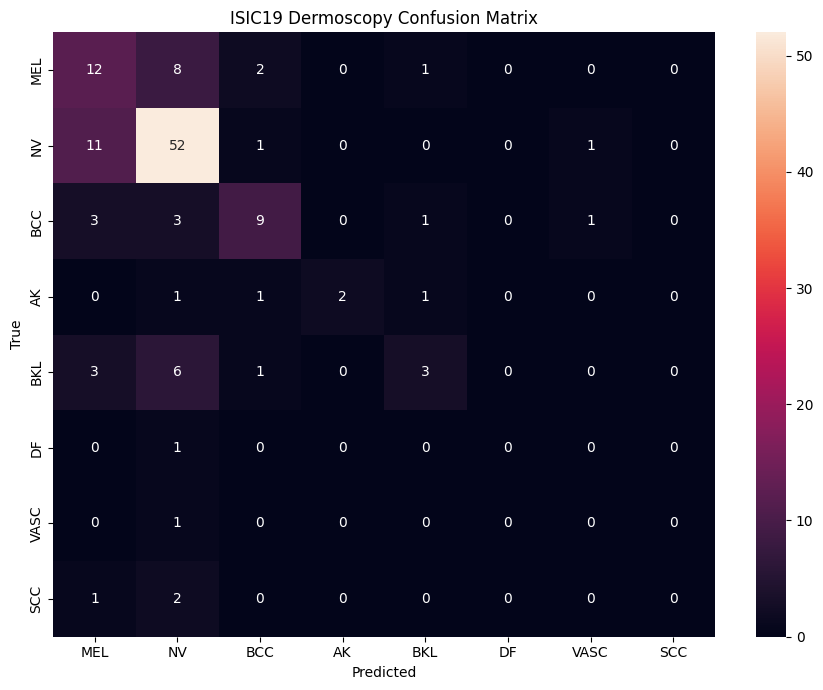

In [17]:
# ============================================================
# 18. BEST MODEL EVALUATION
# ============================================================

best_checkpoint = torch.load(
    OUTPUT_ROOT / "best.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

best_val_metrics = run_supervised_epoch(
    val_loader,
    training=False
)

print("=" * 80)
print("BEST ISIC19 DERMOSCOPY MODEL")
print("=" * 80)

print(
    f"Validation accuracy: "
    f"{best_val_metrics['accuracy']*100:.2f}%"
)

print(
    f"Validation macro-F1: "
    f"{best_val_metrics['macro_f1']:.4f}"
)

print(
    f"Validation AUC: "
    f"{best_val_metrics['auc']:.4f}"
)

print("\nClassification report:")

print(
    classification_report(
        best_val_metrics["y_true"],
        best_val_metrics["y_pred"],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

cm = confusion_matrix(
    best_val_metrics["y_true"],
    best_val_metrics["y_pred"],
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(
    "ISIC19 Dermoscopy Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "confusion_matrix.png",
    dpi=200
)

plt.show()


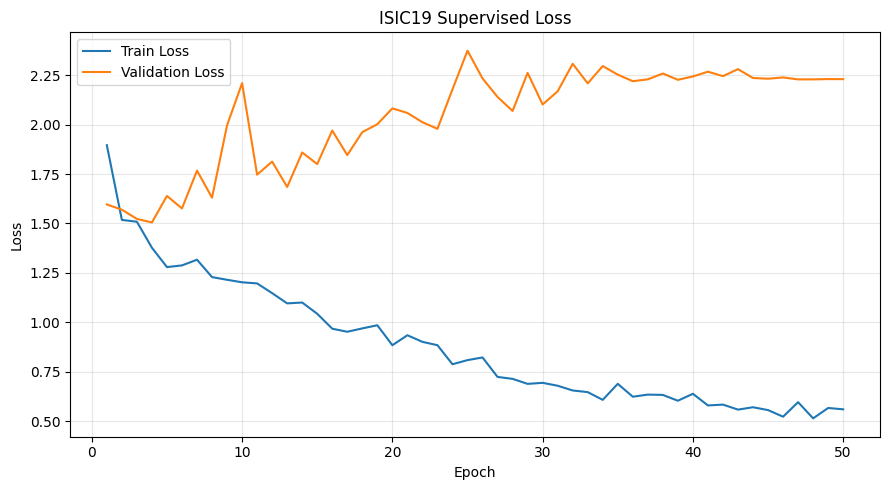

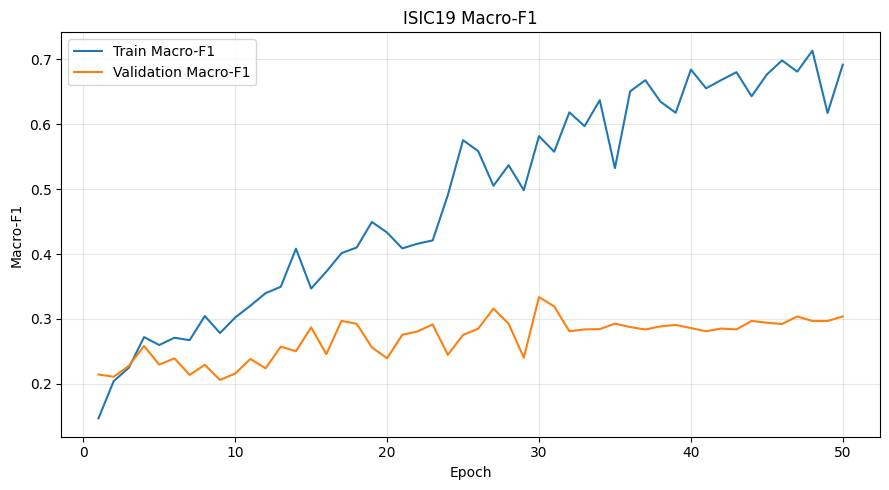

In [18]:
# ============================================================
# 19. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(history)

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ISIC19 Supervised Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "loss_curves.png",
    dpi=200
)

plt.show()


plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"],
    label="Train Macro-F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("ISIC19 Macro-F1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "f1_curves.png",
    dpi=200
)

plt.show()


In [19]:
# ============================================================
# 20. EXPORT TRANSFER-READY DERMOSCOPY ENCODER
# ============================================================

best_checkpoint = torch.load(
    OUTPUT_ROOT / "best.pth",
    map_location="cpu",
    weights_only=False
)

best_model = DermoscopyBranch()

best_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

encoder_state = {
    "hrwe":
        best_model.hrwe.state_dict(),

    "msta":
        best_model.msta.state_dict(),

    "region":
        best_model.region.state_dict()
}

TRANSFER_ENCODER_PATH = (
    OUTPUT_ROOT /
    "RemixFormerPP_ISIC19_Dermoscopy_Encoder_best.pth"
)

torch.save(
    {
        "source":
            "ISIC19 supervised dermoscopy pretraining",

        "initialization":
            "ImageNet -> DINO -> supervised ISIC19",

        "encoder_state_dict":
            encoder_state,

        "architecture": {
            "image_size":
                IMAGE_SIZE,

            "window_size":
                WINDOW_SIZE,

            "num_windows":
                NUM_WINDOWS,

            "embed_dim":
                EMBED_DIM,

            "depth":
                DEPTH,

            "heads":
                NUM_HEADS,

            "patch_size":
                PATCH_SIZE,

            "msta_k":
                MSTA_K
        }
    },
    TRANSFER_ENCODER_PATH
)

summary = {
    "dataset": "ISIC 2019",
    "initialization":
        "ImageNet pretrained ViT-S/16",
    "self_supervised":
        "DINO",
    "supervised_training":
        True,

    "image_size":
        IMAGE_SIZE,

    "window_size":
        WINDOW_SIZE,

    "num_windows":
        NUM_WINDOWS,

    "embed_dim":
        EMBED_DIM,

    "depth":
        DEPTH,

    "heads":
        NUM_HEADS,

    "patch_size":
        PATCH_SIZE,

    "msta_k":
        MSTA_K,

    "dino_epochs":
        DINO_EPOCHS,

    "supervised_epochs":
        SUP_EPOCHS,

    "best_epoch":
        int(best_epoch),

    "best_val_macro_f1":
        float(best_val_f1)
}

with open(
    OUTPUT_ROOT / "training_summary.json",
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )

print("TRANSFER-READY FILES")
print(
    "DINO backbone:",
    DINO_BACKBONE_PATH
)
print(
    "Best supervised model:",
    OUTPUT_ROOT / "best.pth"
)
print(
    "Last supervised model:",
    OUTPUT_ROOT / "last.pth"
)
print(
    "Transfer encoder:",
    TRANSFER_ENCODER_PATH
)


TRANSFER-READY FILES
DINO backbone: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy/DINO_ViT_S16_backbone.pth
Best supervised model: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy/best.pth
Last supervised model: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy/last.pth
Transfer encoder: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy/RemixFormerPP_ISIC19_Dermoscopy_Encoder_best.pth


In [20]:
# ============================================================
# 21. FINAL FILE INVENTORY
# ============================================================

config = {
    "run_trial": RUN_TRIAL,
    "dino_epochs": DINO_EPOCHS,
    "supervised_epochs": SUP_EPOCHS,
    "dino_batch_size": DINO_BATCH_SIZE,
    "supervised_batch_size": SUP_BATCH_SIZE,
    "dino_lr": DINO_LR,
    "supervised_lr": SUP_LR,
    "image_size": IMAGE_SIZE,
    "window_size": WINDOW_SIZE,
    "num_windows": NUM_WINDOWS,
    "embed_dim": EMBED_DIM,
    "depth": DEPTH,
    "heads": NUM_HEADS,
    "patch_size": PATCH_SIZE,
    "msta_k": MSTA_K,
    "num_classes": NUM_CLASSES,
    "initialization": "ImageNet -> DINO -> supervised ISIC19"
}

with open(
    OUTPUT_ROOT / "config.json",
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=2
    )

print("Output directory:", OUTPUT_ROOT)
print()

for file_path in sorted(
    OUTPUT_ROOT.iterdir()
):
    if file_path.is_file():
        size_mb = (
            file_path.stat().st_size /
            (1024 ** 2)
        )

        print(
            f"{file_path.name:55s}"
            f"{size_mb:10.2f} MB"
        )


Output directory: /kaggle/working/remixformerpp_isic19_imagenet_dino_demoscopy

DINO_ViT_S16_backbone.pth                                   82.71 MB
RemixFormerPP_ISIC19_Dermoscopy_Encoder_best.pth           182.16 MB
best.pth                                                   364.27 MB
config.json                                                  0.00 MB
confusion_matrix.png                                         0.08 MB
dino_history.csv                                             0.00 MB
f1_curves.png                                                0.11 MB
history.csv                                                  0.01 MB
last.pth                                                   364.27 MB
loss_curves.png                                              0.10 MB
train_split.csv                                              0.08 MB
training_summary.json                                        0.00 MB
val_split.csv                                                0.02 MB
